In [1]:
from torchvision import transforms
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image as PILImage
import numpy as np
import os
import pandas as pd
import random
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

/data/ramdhavb/venv/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import quantus
from quantus import PointingGame, MaxSensitivity
from quantus.metrics import PixelFlipping
import glob
from PIL import Image

from pytorch_grad_cam.utils.image import preprocess_image, show_cam_on_image
from quantus import norm_func, perturb_func, similarity_func
from datetime import datetime

from xai_lib import MemoryManagement as mm
from xai_lib import AttributionEngine as att_engine
import xaibenchmark as xb
from skimage.segmentation import slic
from skimage.filters import threshold_otsu 


from scipy.ndimage import gaussian_filter
import pickle

In [3]:
name = "ramdhavb"
PREPROCESSED_DIR = f"/data/{name}/preprocessed_idrid"
DRIVE_MODEL_DIR = f"/data/{name}/models"
MODEL_NAMES = ["resnet50", "efficientnetb0"]
LOCALIZATION_SAVE_DIR = f"/data/{name}/localization_xai_maps"
SAVE_DIR = f"/data/{name}/xai_maps"
RESULTS_DIR = f"/data/{name}/results"
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
N_TEST = 81
SEED=42

In [4]:
_engine_cache = {}

def get_engine_for(model):
    """Look up the AttributionEngine that was built for this exact model object."""

    eng = _engine_cache.get(id(model))
    if eng is None:
        raise RuntimeError(
            "No AttributionEngine registered for this model."
        )
    return eng

In [5]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# Lets cuDNN pick the fastest conv algorithms since our input size (224x224) is fixed
torch.backends.cudnn.benchmark = True

cuda


In [7]:
def get_predicted_labels(model, samples, device, transform=test_transform):
    """Recomputes the model's predicted class per sample."""
    preds = []
    model.eval()
    with torch.no_grad():
        for raw_img_np, _ in samples:
            input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to(device)
            pred = model(input_tensor).argmax(dim=1).item()
            preds.append(pred)
    return np.array(preds)

# **Explainable Artificial Intelligence**

**While Grad-CAM is widely applied in DR interpretability literature, disclosed hyperparameters for perturbation-based methods (LIME, SHAP) are rarely reported in DR-specific work.**

Our parameter choices were therefore informed by broader medical-imaging and XAI benchmarking literature rather than DR-specific research, while also accoutning for our resource constraints given the scale of our evaluation.

**For LIME, we set lime_samples=1000**, consistent with values used in [Gastrointestinal Endoscopic study](https://arxiv.org/pdf/2503.00780), [Sickle Cell study](https://arxiv.org/pdf/2305.01663) and [Photonic Chip study](https://arxiv.org/pdf/2505.09266) which set the number of samples to 1000 to ensure the creation of a sufficient number of perturbed samples around the input instance for accurate approximation.

**For SHAP, we set the max_evals =500**, consistent with the [Sickle Cell study](https://arxiv.org/pdf/2305.01663) from above and is also the SHAP libraries default. We also use batch_size-50 which is the SHAP library, the same justification as this study [haematopoietic stem cell study](https://pmc.ncbi.nlm.nih.gov/articles/PMC12746025/)


**We use a 32x32 blur kernel for the SHAP masker, smaller than the 128x128 kernel used in SHAP's reference examples for 224x224 natural images.** In natural-image classification, the relevant object typically occupies a large contiguous region of the frame whereas for DR lesion attribution, multiple small lesions can appear simultaneously across the image. A 128x128 kernel would blur across a majority of the image width in a single masking operation, conflating spatially distinct lesions that should be attributed independently, which is why we choose 32x32

**The XAI Attribution Engine is a single wrapper around three XAI methods, so each trained model can be explained the same way regardless of which method is used. Given a model and an image, it returns an attribution map per method highlighting the regions that most influenced the prediction**

**Loading the Refined IDRID dataset**

In [8]:
def load_preprocessed_from_disk(save_dir):
    """Function to load IDRiD images from the save directory"""
    images_out_dir = os.path.join(save_dir, "images")
    masks_out_dir = os.path.join(save_dir, "masks")

    image_paths = sorted(glob.glob(os.path.join(images_out_dir, "*.png")))
    if not image_paths:
        raise FileNotFoundError(f"No preprocessed images found in {images_out_dir}")

    samples = []
    for img_path in image_paths:
        image_id = os.path.splitext(os.path.basename(img_path))[0]
        mask_path = os.path.join(masks_out_dir, f"{image_id}.png")

        img = np.array(Image.open(img_path).convert('RGB'))
        mask = np.array(Image.open(mask_path).convert('L'))
        samples.append((img, mask))
    return samples

In [9]:
idrid_subset = load_preprocessed_from_disk(PREPROCESSED_DIR)

# **Side-by-Side Comparison of each XAI technique**

--- resnet50 ---


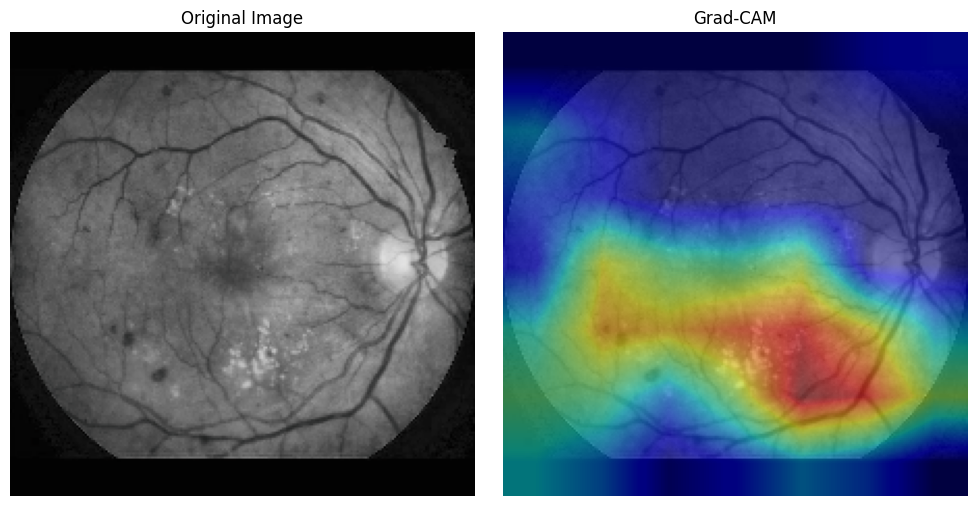

  0%|          | 0/498 [00:00<?, ?it/s]

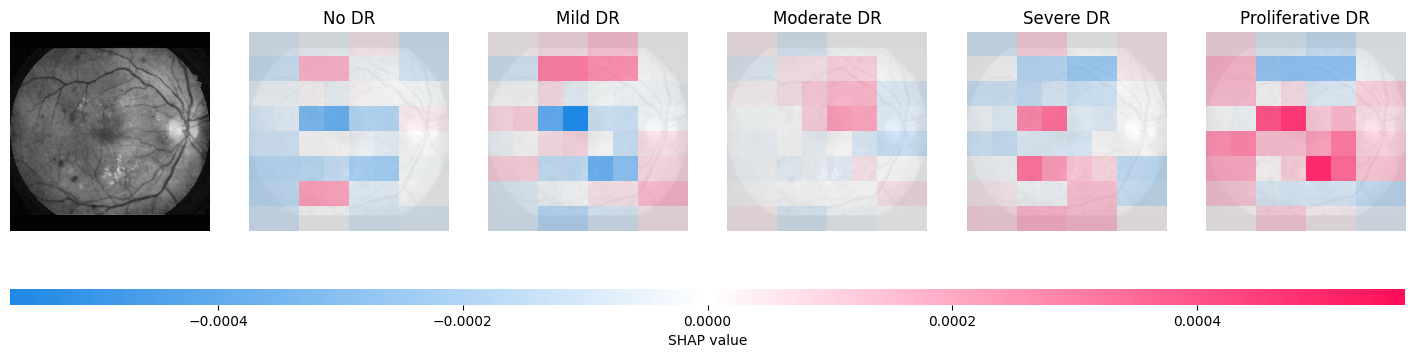

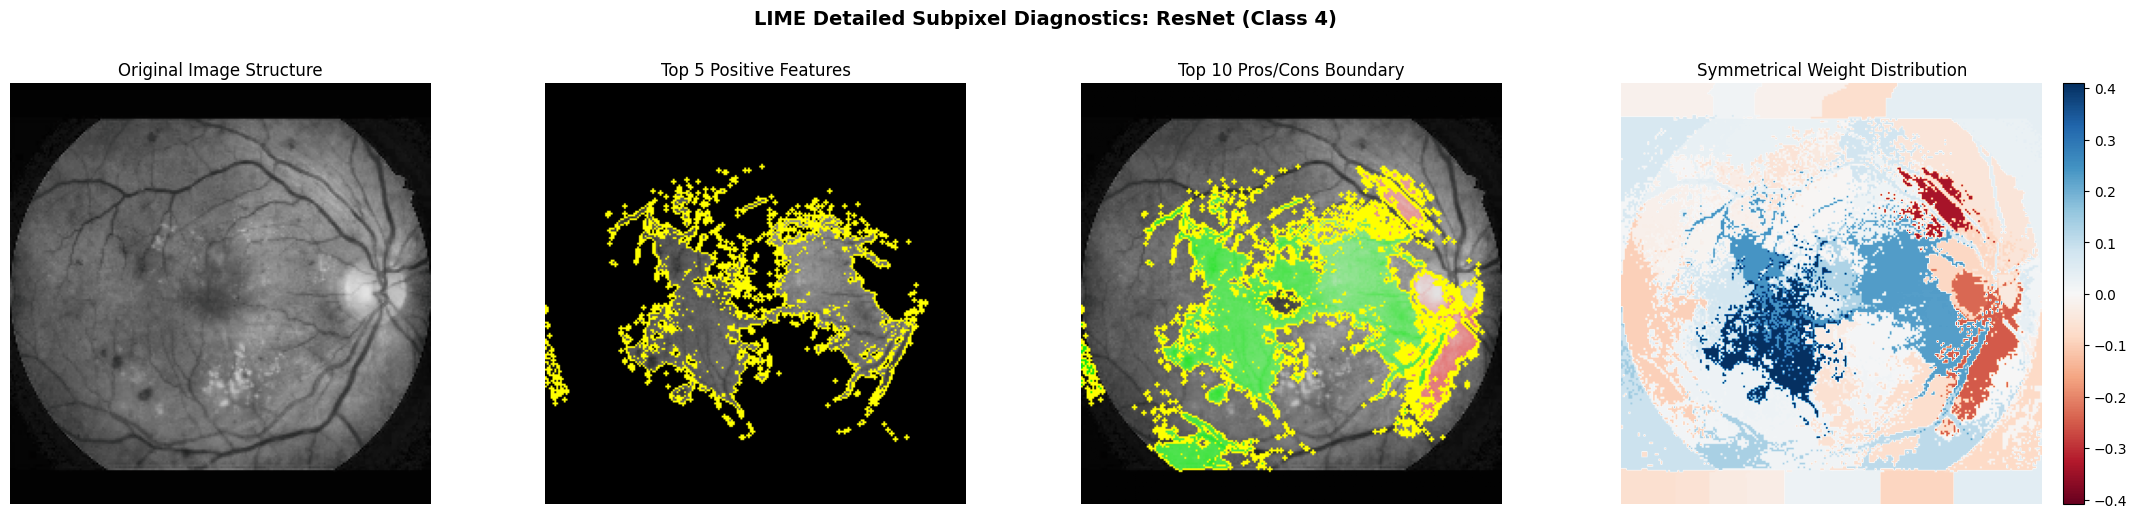

[mem after unloading resnet50 (viz cell)] allocated=0.02 GB  reserved=0.04 GB
[mem after unloading resnet50 (viz cell)] allocated=0.02 GB  reserved=0.04 GB


--- efficientnetb0 ---


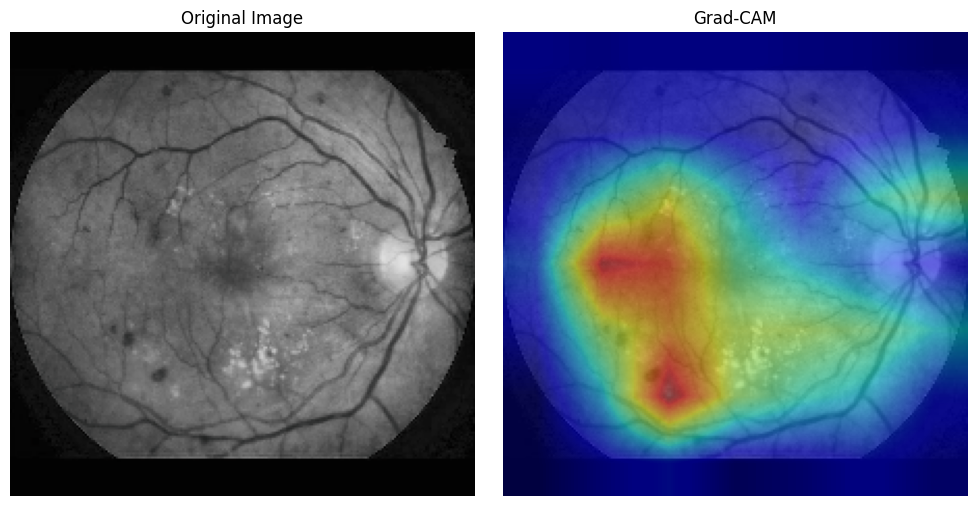

  0%|          | 0/498 [00:00<?, ?it/s]

 25%|██▍       | 124/498 [00:02<00:07, 48.25it/s]

 35%|███▍      | 174/498 [00:02<00:04, 70.77it/s]

 45%|████▍     | 224/498 [00:02<00:02, 98.25it/s]

 55%|█████▌    | 274/498 [00:02<00:01, 129.81it/s]

...

 85%|████████▌ | 424/498 [00:03<00:00, 234.14it/s]

 95%|█████████▌| 474/498 [00:03<00:00, 266.48it/s]

524it [00:03, 293.02it/s]                         

PartitionExplainer explainer: 100%|██████████| 1/1 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:14, 14.42s/it]               

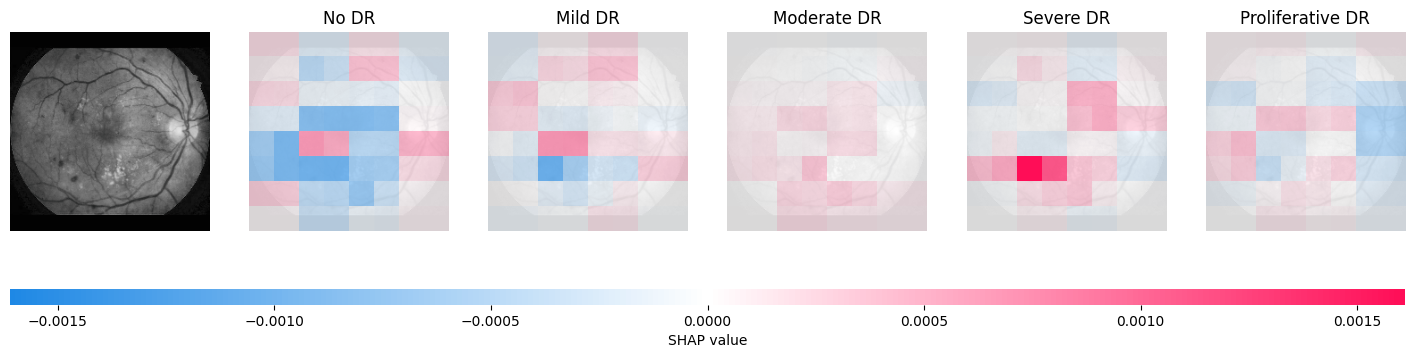

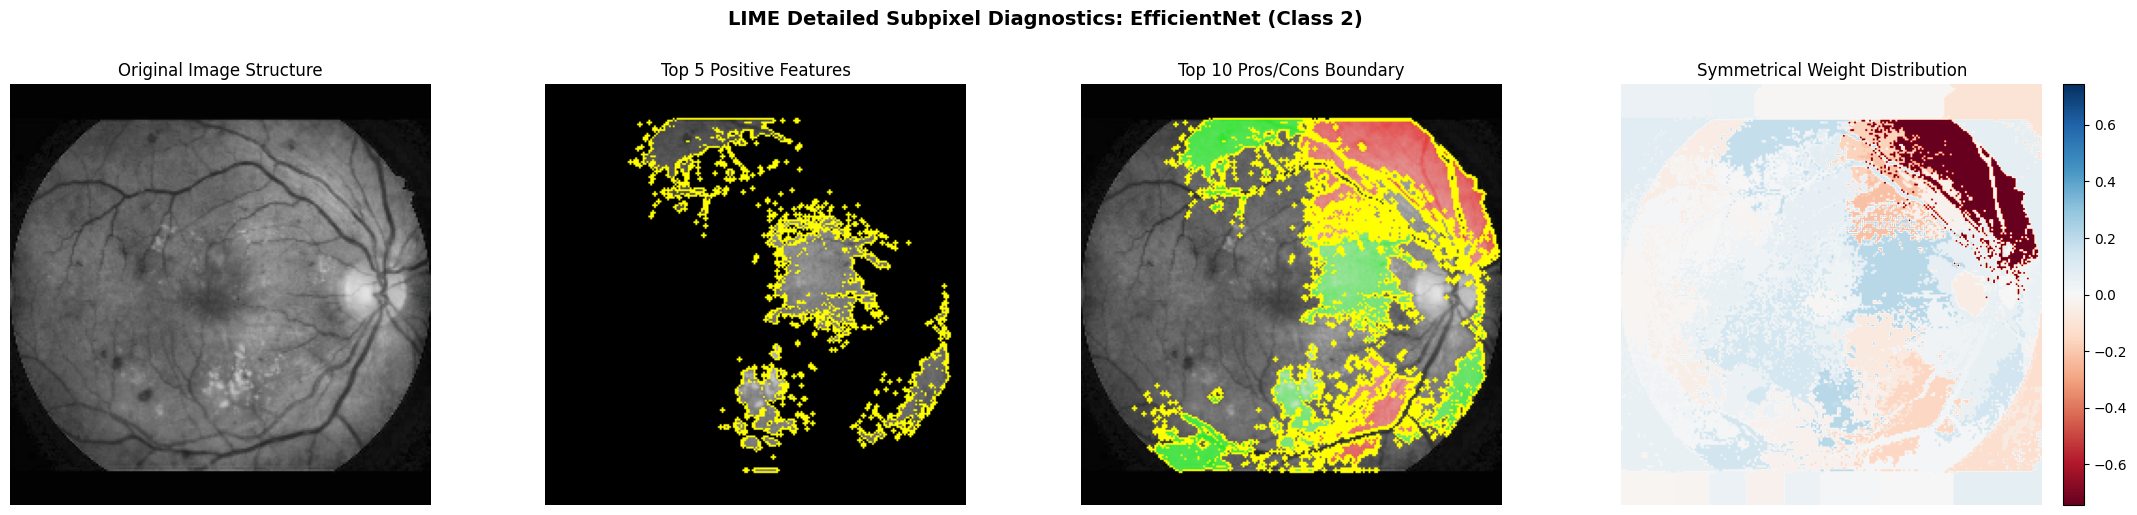

[mem after unloading efficientnetb0 (viz cell)] allocated=0.02 GB  reserved=0.04 GB
[mem after unloading efficientnetb0 (viz cell)] allocated=0.02 GB  reserved=0.04 GB


In [10]:
raw_image, lesion_mask = idrid_subset[0]  # Sample image
os.makedirs(FIGURES_DIR, exist_ok=True)

for model_name in MODEL_NAMES:
    drive_weight_path = os.path.join(DRIVE_MODEL_DIR, f"{model_name}_best_model.pth")
    model = mm.load_model(model_name, drive_weight_path, device)

    engine = att_engine.AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    image_tensor = test_transform(PILImage.fromarray(raw_image))
    with torch.no_grad():
        predicted_class = model(image_tensor.unsqueeze(0).to(device)).argmax(dim=1).item()

    raw_img_uint8 = engine.unnormalize_to_uint8(image_tensor)
    img_batched = image_tensor.unsqueeze(0).to(device)

    print(f"--- {model_name} ---")

    engine.show_grad_cam(img_batched, raw_img_uint8, predicted_class)
    plt.savefig(os.path.join(FIGURES_DIR, f"gradcam_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    engine.show_shap(raw_img_uint8, target_class=predicted_class, all_classes=True)
    plt.savefig(os.path.join(FIGURES_DIR, f"shap_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    engine.show_lime(raw_img_uint8, target_class=predicted_class)
    plt.savefig(os.path.join(FIGURES_DIR, f"lime_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    mm.unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    mm.gpu_mem_report(f"after unloading {model_name} (viz cell)")

    del image_tensor, img_batched, raw_img_uint8

    _engine_cache.clear()
    mm.gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()
    mm.gpu_mem_report(f"after unloading {model_name} (viz cell)")

In [11]:
def _per_image_dir(save_dir, model_name):
    d = os.path.join(save_dir, f"{model_name}_per_image")
    os.makedirs(d, exist_ok=True)
    return d


def run_attributions_on_samples(engine, samples, transform, save_dir, model_name, desc="XAI"):
    """Generating attribution maps using faithfulness normalisation (MinMax normalisation)"""
    per_image_dir = _per_image_dir(save_dir, model_name)

    for i, (raw_img, label) in enumerate(tqdm(samples, desc=desc, ncols=90)):
        img_path = os.path.join(per_image_dir, f"image_{i:04d}.npz")
        if os.path.exists(img_path):
            continue  

        img_tensor = transform(PILImage.fromarray(raw_img))
        try:
            maps = engine.compute_all(img_tensor, label)
            tmp_path = os.path.join(per_image_dir, f"image_{i:04d}.tmp.npz")  
            np.savez(
                tmp_path,
                lime=maps['lime'],
                shap=maps['shap'],
                gradcam=maps['gradcam'],
                label=label,
            )
            os.replace(tmp_path, img_path)
        finally:
            img_tensor = None
            mm.clear_memory()
            if i % 5 == 0:
                mm.log_rss(f"{desc}/image {i}")

def run_localization_attributions_on_samples(engine, samples, transform, save_dir, model_name, desc="XAI"):
    """Generating attribution maps using localisation normalisation (clipping out zero attributions and MinMax normalisation)"""
    per_image_dir = _per_image_dir(save_dir, model_name)

    for i, (raw_img, label) in enumerate(tqdm(samples, desc=desc, ncols=90)):
        img_path = os.path.join(per_image_dir, f"image_{i:04d}.npz")
        if os.path.exists(img_path):
            continue  

        img_tensor = transform(PILImage.fromarray(raw_img))
        try:
            maps = engine.localization_compute_all(img_tensor, label)
            tmp_path = os.path.join(per_image_dir, f"image_{i:04d}.tmp.npz")
            np.savez(
                tmp_path,
                lime=maps['lime'],
                shap=maps['shap'],
                gradcam=maps['gradcam'],
                label=label,
            )
            os.replace(tmp_path, img_path)
        finally:
            img_tensor = None
            mm.clear_memory()
            if i % 5 == 0:
                mm.log_rss(f"{desc}/image {i}")


def assemble_attribution_results(save_dir, model_name, n_images):
    """Reloads each image's saved LIME/SHAP/Grad-CAM maps and labels from the per-image checkpoint .npz files into lists in image order"""
    per_image_dir = _per_image_dir(save_dir, model_name)
    lime_maps, shap_maps, gradcam_maps, labels = [], [], [], []
    for i in range(n_images):
        img_path = os.path.join(per_image_dir, f"image_{i:04d}.npz")
        with np.load(img_path) as d:
            lime_maps.append(d['lime'])
            shap_maps.append(d['shap'])
            gradcam_maps.append(d['gradcam'])
            labels.append(d['label'])   
    return {
        'lime': lime_maps,
        'shap': shap_maps,
        'gradcam': gradcam_maps,
        'labels': labels,
    }

 **Computing attribution maps used for localization tests that uses a different normaliastion to faithfulness**

  This cell only runs if attribution maps have not been generated yet

In [12]:
os.makedirs(LOCALIZATION_SAVE_DIR, exist_ok=True)

test_samples = idrid_subset[:N_TEST]

for model_name in MODEL_NAMES:
    save_path = os.path.join(LOCALIZATION_SAVE_DIR, f"localization_attribution_maps_{model_name}_test.npz")

    if os.path.exists(save_path):
        print(f"\nFound existing maps for {model_name} at {save_path}. Skipping generation.")
        continue

    print(f"\n{'='*60}\n  Computing attribution maps | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(DRIVE_MODEL_DIR, f"{model_name}_best_model.pth")
    model = mm.load_model(model_name, drive_weight_path, device)

    engine = att_engine.AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    n_already_done = len([
        f for f in os.listdir(_per_image_dir(LOCALIZATION_SAVE_DIR, model_name))
        if f.endswith(".npz")
    ]) if os.path.isdir(_per_image_dir(LOCALIZATION_SAVE_DIR, model_name)) else 0
    print(f"  {n_already_done}/{len(test_samples)} images already checkpointed for {model_name}; resuming...")

    run_localization_attributions_on_samples(
        engine, test_samples, test_transform,
        save_dir=LOCALIZATION_SAVE_DIR, model_name=model_name,
        desc=f"XAI maps ({model_name})",
    )

    attribution_results = assemble_attribution_results(LOCALIZATION_SAVE_DIR, model_name, len(test_samples))

    gts           = np.stack(attribution_results['labels'], axis=0)
    gradcam_maps  = np.stack(attribution_results['gradcam'], axis=0)
    lime_maps     = np.stack(attribution_results['lime'], axis=0)
    shap_maps     = np.stack(attribution_results['shap'], axis=0)

    np.savez(save_path, gts=gts, gradcam=gradcam_maps, lime=lime_maps, shap=shap_maps)
    print(f"Saved {N_TEST} images' attribution maps to {save_path}")

    del attribution_results, gts, gradcam_maps, lime_maps, shap_maps

    mm.unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    mm.gpu_mem_report(f"after unloading {model_name}")


  Computing attribution maps | Model: resnet50


  0/81 images already checkpointed for resnet50; resuming...


[rss XAI maps (resnet50)/image 0] peak RSS so far = 5439 MB  |  GPU allocated = 296 MB


[rss XAI maps (resnet50)/image 5] peak RSS so far = 5439 MB  |  GPU allocated = 296 MB


[rss XAI maps (resnet50)/image 10] peak RSS so far = 5439 MB  |  GPU allocated = 297 MB


...

[rss XAI maps (efficientnetb0)/image 70] peak RSS so far = 5439 MB  |  GPU allocated = 139 MB


[rss XAI maps (efficientnetb0)/image 75] peak RSS so far = 5439 MB  |  GPU allocated = 139 MB


[rss XAI maps (efficientnetb0)/image 80] peak RSS so far = 5439 MB  |  GPU allocated = 139 MB


Saved 81 images' attribution maps to /data/ramdhavb/localization_xai_maps/localization_attribution_maps_efficientnetb0_test.npz


[mem after unloading efficientnetb0] allocated=0.02 GB  reserved=0.04 GB


 **Computing attribution maps used for faithfulness tests that use a different normalisation to localisation**

 This cell only runs if attribution maps have not been generated yet

In [13]:
os.makedirs(SAVE_DIR, exist_ok=True)

test_samples = idrid_subset[:N_TEST]

for model_name in MODEL_NAMES:
    save_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")

    if os.path.exists(save_path):
        print(f"\nFound existing maps for {model_name} at {save_path}. Skipping generation.")
        continue

    print(f"\n{'='*60}\n  Computing attribution maps | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(DRIVE_MODEL_DIR, f"{model_name}_best_model.pth")
    model = mm.load_model(model_name, drive_weight_path, device)

    engine = att_engine.AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    n_already_done = len([
        f for f in os.listdir(_per_image_dir(SAVE_DIR, model_name))
        if f.endswith(".npz")
    ]) if os.path.isdir(_per_image_dir(SAVE_DIR, model_name)) else 0
    print(f"  {n_already_done}/{len(test_samples)} images already checkpointed for {model_name}; resuming...")

    run_attributions_on_samples(
        engine, test_samples, test_transform,
        save_dir=SAVE_DIR, model_name=model_name,
        desc=f"XAI maps ({model_name})",
    )

    attribution_results = assemble_attribution_results(SAVE_DIR, model_name, len(test_samples))

    gts           = np.stack(attribution_results['labels'], axis=0)
    gradcam_maps  = np.stack(attribution_results['gradcam'], axis=0)
    lime_maps     = np.stack(attribution_results['lime'], axis=0)
    shap_maps     = np.stack(attribution_results['shap'], axis=0)

    np.savez(save_path, gts=gts, gradcam=gradcam_maps, lime=lime_maps, shap=shap_maps)
    print(f"Saved {N_TEST} images' attribution maps to {save_path}")

    del attribution_results, gts, gradcam_maps, lime_maps, shap_maps

    mm.unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    mm.gpu_mem_report(f"after unloading {model_name}")


  Computing attribution maps | Model: resnet50


  0/81 images already checkpointed for resnet50; resuming...


[rss XAI maps (resnet50)/image 0] peak RSS so far = 5439 MB  |  GPU allocated = 296 MB


[rss XAI maps (resnet50)/image 5] peak RSS so far = 5439 MB  |  GPU allocated = 296 MB


[rss XAI maps (resnet50)/image 10] peak RSS so far = 5439 MB  |  GPU allocated = 297 MB


...

[rss XAI maps (efficientnetb0)/image 70] peak RSS so far = 5439 MB  |  GPU allocated = 139 MB


[rss XAI maps (efficientnetb0)/image 75] peak RSS so far = 5439 MB  |  GPU allocated = 139 MB


[rss XAI maps (efficientnetb0)/image 80] peak RSS so far = 5439 MB  |  GPU allocated = 139 MB


Saved 81 images' attribution maps to /data/ramdhavb/xai_maps/attribution_maps_efficientnetb0_test.npz


[mem after unloading efficientnetb0] allocated=0.02 GB  reserved=0.04 GB


# **Localization Evaluation: The pointing game and IoU**


**Pointing Game**: Takes the single highest-attribution pixel in the explanation map and checks if it falls inside the ground-truth lesion region. Scores 1 if yes, 0 if no. It's a strict, all-or-nothing test of whether the model's single most important pixel is disease-relevant.

**IoU**: Measures a model's localization performance by calculating the ratio of the overlap area to the combined total area of the predicted bounding box and the ground-truth bounding box

Two binarisation threhsolds used: **Adaptive Thresholding and Otsu Thresholding**


In [14]:
def binarize_map_adaptive(attribution_map, gt_mask):
    """Adaptive thresholding determined using number of pixels in ground truth lesion mask"""
    m = np.asarray(attribution_map, dtype=np.float32)
    n = int(np.asarray(gt_mask).sum())

    if n <= 0:
        return np.zeros_like(m, dtype=np.uint8)
    if n >= m.size:
        return (m > 0).astype(np.uint8)

    top_k_frac = n / m.size
    cutoff = np.percentile(m, 100.0 * (1.0 - top_k_frac))
    return ((m >= cutoff) & (m > 0)).astype(np.uint8)

def binarize_map_otsu(attribution_map):
    """Per-image Otsu thresholding using skimage."""
    m = np.asarray(attribution_map, dtype=np.float32)

    if np.all(m == m[0, 0]):
        return np.zeros_like(m, dtype=np.uint8)
        
    try:
        thresh = threshold_otsu(m)
        return (m > thresh).astype(np.uint8)
    except ValueError:
        return np.zeros_like(m, dtype=np.uint8)

def binarize_map_batch_adaptive(maps, gts):
    """Each map is thresholded using its own GT pixel count rather than a global threshold value."""
    assert maps.shape[0] == gts.shape[0]
    return np.stack([binarize_map_adaptive(maps[i], gts[i]) for i in range(maps.shape[0])], axis=0)

def binarize_map_batch_otsu(maps, gts):
    """Each map is thresholded using Otsu Thresholding"""
    assert maps.shape[0] == gts.shape[0]
    return np.stack([binarize_map_otsu(maps[i]) for i in range(maps.shape[0])], axis=0)

localization_rows = []

for model_name in MODEL_NAMES:
    load_path = os.path.join(LOCALIZATION_SAVE_DIR, f"localization_attribution_maps_{model_name}_test.npz")
    data = np.load(load_path)
    gts, gradcam_maps, lime_maps, shap_maps = data['gts'], data['gradcam'], data['lime'], data['shap']

    maps_dict = {"gradcam": gradcam_maps, "lime": lime_maps, "shap": shap_maps}

    print(f"=== {model_name} ===")
    for method, cont_maps in maps_dict.items():
        #Thresholding the maps
        bin_maps_adaptive = binarize_map_batch_adaptive(cont_maps, gts)
        bin_maps_otsu = binarize_map_batch_otsu(cont_maps,gts)

        #Running xaibenchmark package to get IoU, PG, and Recall
        pointing_game = xb.hit(cont_maps, gts)
        iou_score_adaptive  = xb.iou(bin_maps_adaptive, gts)
        iou_score_otsu = xb.iou(bin_maps_otsu, gts)
        recall_adaptive = xb.recall(bin_maps_adaptive, gts)
        recall_otsu     = xb.recall(bin_maps_otsu, gts)

        print(f"--- {method} ---")
        print(f"Pointing Game           : {pointing_game:.4f}")
        print(f"Adaptive Threshold IoU                     : {iou_score_adaptive :.4f}\n")
        print(f"Otsu Threshold IoU                     : {iou_score_otsu:.4f}\n")
        print(f"Adaptive Threshold Recall : {recall_adaptive:.4f}")
        print(f"Otsu Threshold Recall     : {recall_otsu:.4f}\n")
        

        localization_rows.append({
            'model': model_name,
            'method': method,
            'pointing_game': round(pointing_game, 4),
            'iou_adaptive': round(iou_score_adaptive, 4),
            'iou_otsu': round(iou_score_otsu, 4),
            'recall_adaptive': round(recall_adaptive, 4),
            'recall_otsu': round(recall_otsu, 4),
        })

localization_df = pd.DataFrame(localization_rows)
display(localization_df)

=== resnet50 ===


--- gradcam ---
Pointing Game           : 0.0864
Adaptive Threshold IoU                     : 0.0513

Otsu Threshold IoU                     : 0.0693

Adaptive Threshold Recall : 0.0901
Otsu Threshold Recall     : 0.4635



--- lime ---
Pointing Game           : 0.5556
Adaptive Threshold IoU                     : 0.0279

Otsu Threshold IoU                     : 0.0394

Adaptive Threshold Recall : 0.0597
Otsu Threshold Recall     : 0.2139



--- shap ---
Pointing Game           : 0.7160
Adaptive Threshold IoU                     : 0.0602

Otsu Threshold IoU                     : 0.0654

Adaptive Threshold Recall : 0.1162
Otsu Threshold Recall     : 0.3080

=== efficientnetb0 ===


--- gradcam ---
Pointing Game           : 0.2222
Adaptive Threshold IoU                     : 0.0866

Otsu Threshold IoU                     : 0.0852

Adaptive Threshold Recall : 0.1498
Otsu Threshold Recall     : 0.5308



--- lime ---
Pointing Game           : 0.7778
Adaptive Threshold IoU                     : 0.0527

Otsu Threshold IoU                     : 0.0618

Adaptive Threshold Recall : 0.1116
Otsu Threshold Recall     : 0.3244



--- shap ---
Pointing Game           : 0.7160
Adaptive Threshold IoU                     : 0.0662

Otsu Threshold IoU                     : 0.0703

Adaptive Threshold Recall : 0.1281
Otsu Threshold Recall     : 0.3612



,model,method,pointing_game,iou_adaptive,iou_otsu,recall_adaptive,recall_otsu
0,resnet50,gradcam,0.0864,0.0513,0.0693,0.0901,0.4635
1,resnet50,lime,0.5556,0.0279,0.0394,0.0597,0.2139
2,resnet50,shap,0.7160,0.0602,0.0654,0.1162,0.3080
3,efficientnetb0,gradcam,0.2222,0.0866,0.0852,0.1498,0.5308
4,efficientnetb0,lime,0.7778,0.0527,0.0618,0.1116,0.3244
5,efficientnetb0,shap,0.7160,0.0662,0.0703,0.1281,0.3612


In [15]:
os.makedirs(RESULTS_DIR, exist_ok=True)
localization_df.to_csv(os.path.join(RESULTS_DIR, "localization_summary.csv"), index=False)
print(f"Saved localization summary to {os.path.join(RESULTS_DIR, 'localization_summary.csv')}")

Saved localization summary to /data/ramdhavb/results/localization_summary.csv


In [16]:
_trapz = getattr(np, "trapezoid", None) or np.trapz

In [17]:
def load_attribution_maps(save_dir, model_name, filename_template="attribution_maps_{model}_test.npz"):
    """Loads precomputed attribution maps for one model from disk."""
    with np.load(os.path.join(save_dir, filename_template.format(model=model_name))) as data:
        method_maps = {
            "LIME": np.array(data['lime']),
            "GradCAM": np.array(data['gradcam']),
            "SHAP": np.array(data['shap']),
        }
    return method_maps

# **Faithfulness Evaluation: IROF**

Gradually remove the image regions identified as most important by the XAI method. If the model's confidence drops significantly, it shows those regions were genuinely important, meaning the explanation is more faithful.

**Aknowledgements:** [IROF Implementation](http://github.com/woahitsdona/Quantitative-Evaluation-of-XAI-Methods-for-Image-Segmentation-in-Autonomous-Driving/tree/main)

In [18]:
def compute_dataset_mean(images, transform):
    """Returns the mean colour of the dataset"""
    total = torch.zeros(3, dtype=torch.float64)
    n_pixels=0
    for img in images:
        x = transform(PILImage.fromarray(img)).double()
        total+=x.sum(dim=(1,2))
        n_pixels+= x.shape[1]*x.shape[2]
    return (total/n_pixels).float().view(1,3,1,1)

dataset = [img for img, _ in idrid_subset]
dataset_mean = compute_dataset_mean(dataset,test_transform )


**The original IROF paper uses SLIC to segment images into regions**

In [19]:
class FastIROF:
    def __init__(self, model, device, n_segments=100, compactness=10, sigma=1, max_regions=100, dataset_mean=None):
        """Initialize IROF evaluator with model and segmentation parameters"""
        self.model = model.to(device)
        self.device = device
        self.n_segments = n_segments    # SLIC: approximate target number of segments
        self.compactness = compactness  # SLIC: balances color proximity vs. spatial proximity
        self.sigma = sigma              # Gaussian smoothing applied before segmenting
        self.max_regions = max_regions  # Max number of regions to evaluate

        # ImageNet normalization stats used to invert test_transform before segmenting,
        # so SLIC sees real pixel colours/edges instead of normalized (mean-0) values.
        self._imagenet_mean = np.array([0.485, 0.456, 0.406])
        self._imagenet_std = np.array([0.229, 0.224, 0.225])
        self.dataset_mean = dataset_mean

    def perturb(self, image, mask):
        """Replace selected region in the image with the dataset mean colour (baseline)"""
        baseline = self.dataset_mean.to(image.device)
        image = image.clone()

        if mask.shape != (image.shape[2], image.shape[3]):
            raise ValueError(f"Mask shape {mask.shape} does not match image shape {(image.shape[2], image.shape[3])}")

        mask = mask.unsqueeze(0).unsqueeze(0)  # Add batch and channel dims
        mask = mask.expand_as(image)  # Match shape to image

        # Apply perturbation: replace masked area with baseline
        image = torch.where(mask.bool(), baseline, image)
        return image

    def segment_image(self, x):
        """Segment the original input image (not the attribution map)"""
        img_np = x.squeeze(0).permute(1, 2, 0).cpu().numpy()
        img_np = img_np * self._imagenet_std + self._imagenet_mean  # undo normalization
        img_np = np.clip(img_np, 0.0, 1.0)

        segments = slic(
            img_np.astype(np.float64),
            n_segments=self.n_segments,
            compactness=self.compactness,
            sigma=self.sigma,
            channel_axis=-1,   # img_np is now a real 3-channel RGB image, not a 1-channel map
            start_label=0,
        )
        return segments

    def apply(self, x, a, y, segments, batch_size=8, order="morf", seed=42):
        """order="morf" (Most-Relevant-First) removes regions in DECREASING order of attribution score
        order="random" removes regions in a fixed random order and is only meant to used as a baseline to compare against"""
        if order not in ("morf", "random"):
            raise ValueError(f"order must be 'morf' or 'random', got {order!r}")

        x = x.to(self.device)
        y = y.to(self.device)

        a = a.squeeze()
        if a.ndim == 3:
            a = a.mean(axis=0)

        if a.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Attribution shape {a.shape} does not match image size {(x.shape[2], x.shape[3])}")
        if segments.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Segments shape {segments.shape} does not match image size {(x.shape[2], x.shape[3])}")

        # Get original model score for the target class
        with torch.no_grad():
            output = self.model(x)
            orig_score = F.softmax(output, dim=1) * y  # Element-wise multiplication with target mask
            orig_score = orig_score.sum().item()

        # Compute average ATTRIBUTION value within each (fixed, image-derived) region --
        region_scores = [(seg_id, a[segments == seg_id].mean()) for seg_id in np.unique(segments)]

        if order == "morf":
            # Sort by attribution score, HIGHEST first -- remove the regions the
            # explanation thinks are most important first. This is what makes it IROF.
            region_scores.sort(key=lambda pair: pair[1], reverse=True)
        else:  # order == "random"
            rng = np.random.RandomState(seed)
            rng.shuffle(region_scores)

        # Optionally limit number of evaluated regions
        if len(region_scores) > self.max_regions:
            region_scores = region_scores[:self.max_regions]

        scores = [orig_score]

        # Mask of all regions removed so far
        cumulative_mask = np.zeros_like(segments, dtype=np.uint8)

        with torch.no_grad():
            batch_buffer = []
            for seg_id, _ in region_scores:
                # Adding this region to the mask and building the image with all the removed regions replaced by the baseline
                cumulative_mask[segments == seg_id] = 1
                batch_buffer.append(self.perturb(x.clone(), torch.from_numpy(cumulative_mask).to(self.device)))
    
                if len(batch_buffer) == batch_size:
                    batch = torch.stack(batch_buffer).squeeze(1)
                    output = self.model(batch)
                    for out in output:
                        # Softmax probability of the target class for each perturbed image
                        score = F.softmax(out, dim=0) * y.squeeze()
                        scores.append(score.sum().item())
                    batch_buffer = []
                    del batch, output # free memory

            if batch_buffer:  # leftover partial batch
                # Score the remaining images that didnt fill a whole batch 
                batch = torch.stack(batch_buffer).squeeze(1)
                output = self.model(batch)
                for out in output:
                    score = F.softmax(out, dim=0) * y.squeeze()
                    scores.append(score.sum().item())
                del batch, output

        # Divide by the original score so the curve starts at 1.0 
        eps = 1e-8
        normalized_scores = [s / (orig_score + eps) for s in scores]

        return scores, normalized_scores, segments


def resample_curve(curve, n_points=21):
    x_orig = np.linspace(0, 1, len(curve))
    x_new = np.linspace(0, 1, n_points)
    return np.interp(x_new, x_orig, curve)

In [20]:
def run_irof_on_image(irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx,
                       num_classes=5, transform=test_transform):
    """Runs MoRF IROF for one image, across every attribution method."""

    input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to("cpu")

    # One-hot mask selecting the model's predicted class
    out_max = torch.zeros(1, num_classes)
    out_max[0, predicted_class] = 1

    image_segments = irof_evaluator.segment_image(input_tensor)# Segment the original image once, reuse across all methods

    rows = []
    sorted_curves = {}
    random_curves = {}

    for method_name, maps_array in method_maps.items():
        # Loading attribution map of method
        attr_map = torch.tensor(maps_array[img_idx], dtype=torch.float32)

        # Run IROF twice for most relevant first (MoRF) and random order baseline
        _, norm_scores_sorted, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max, segments=image_segments, order="morf")
        _, norm_scores_random, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max, segments=image_segments, order="random")

        # Resample to a fixed number of points so the curves from different images can be averaged
        resampled_sorted = resample_curve(norm_scores_sorted)
        resampled_random = resample_curve(norm_scores_random)

        sorted_curves[method_name] = resampled_sorted
        random_curves[method_name] = resampled_random

        # IROF AUC of MoRF curve
        irof_auc = float(_trapz(resampled_sorted) / (len(resampled_sorted) - 1))
        rows.append({
            'method':          method_name,
            'image_index':     img_idx,
            'predicted_class': predicted_class,
            'irof_auc':        round(irof_auc, 4),
            'num_regions':     len(np.unique(image_segments))
        })
        del attr_map

    # Free up memory before next image
    del input_tensor, out_max, image_segments
    mm.clear_memory()
    
    return rows, sorted_curves, random_curves

In [21]:
def run_irof_evaluation(model, samples, predicted_labels, method_maps, device,
                         n_segments=100, compactness=10, sigma=1, max_regions=100,
                         desc="IROF",dataset_mean=None):
    """Runs the full IROF faithfulness evaluation over samples."""

    # Initializing IROF evaluator used for all images
    irof_evaluator = FastIROF(model=model, device=device, n_segments=n_segments,
                               compactness=compactness, sigma=sigma, max_regions=max_regions,
                               dataset_mean=dataset_mean)

    all_rows = []
    curves = {m: [] for m in method_maps}
    random_curves = {m: [] for m in method_maps}

    for img_idx in tqdm(range(len(samples)), desc=desc, ncols=90):
        raw_img_np, _ = samples[img_idx]

        # Using the model's predicted class
        predicted_class = int(predicted_labels[img_idx])

        # Runs IROF on this image for every attribution method
        rows, sorted_curves_i, random_curves_i = run_irof_on_image(
            irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx
        )

        # Collects image results
        all_rows.extend(rows)
        for method_name in method_maps:
            curves[method_name].append(sorted_curves_i[method_name])
            random_curves[method_name].append(random_curves_i[method_name])

    full_df = pd.DataFrame(all_rows)
    return full_df, curves, random_curves

# **Why max_regions=100?**
Limiting to 100 regions ensures a good balance between spatial resolution and runtime efficiency. This number is sufficient to capture meaningful attribution patterns without over-segmenting the image or introducing noise from very small, low-relevance regions. At the same time, it limits the number of model evaluations during IROF scoring, keeping runtime manageable.

This choice follows common practice (e.g., skimage library).

In [22]:
def summarize_and_save_irof(full_df, results_dir, tag="test"):
    """Aggregates per-image IROF results into a per-method summary."""

    summary = (full_df.groupby('method').agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'),
             n_images=('irof_auc', 'count')).reset_index().sort_values('mean_irof_auc')
    )

    summary['mean_irof_auc'] = summary['mean_irof_auc'].round(4)
    summary['std_irof_auc'] = summary['std_irof_auc'].round(4)

    os.makedirs(results_dir, exist_ok=True)
    now = datetime.now().strftime("%Y-%m-%d")
    full_path = os.path.join(results_dir, f'irof_full_{tag}_{now}.csv')
    summary_path = os.path.join(results_dir, f'irof_summary_{tag}_{now}.csv')

    full_df.to_csv(full_path, index=False)
    summary.to_csv(summary_path, index=False)

    print(f"Saved per-image results to {full_path}")
    print(f"Saved summary to {summary_path}")

    return summary

In [23]:
def plot_irof_curves(curves, n_images, title_suffix=""):
    """Plots the mean score-drop curve per method."""

    plt.figure(figsize=(10, 6))
    n_resample_points = len(next(iter(curves.values()))[0])
    fraction_removed = np.linspace(0, 1, n_resample_points)

    for method_name, method_curves in curves.items():
        mean_curve = np.array(method_curves).mean(axis=0)
        plt.plot(fraction_removed, mean_curve, marker="o", markersize=3, label=method_name)

    plt.title(f"IROF Score Drop Comparison{title_suffix} ({n_images} images)")
    plt.xlabel("Fraction of Regions Removed")
    plt.ylabel("Mean Normalized Prediction Score (1.0 = original confidence)")
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()
    plt.close() 


def plot_irof_bar(summary, title_suffix=""):
    """Plots a bar chart of mean IROF AUC per method."""
    plt.figure(figsize=(7, 5))
    plt.bar(summary['method'], summary['mean_irof_auc'])
    plt.ylabel("Mean IROF AUC (normalized, lower = more faithful)")
    plt.title(f"Faithfulness Comparison by Attribution Method{title_suffix}")
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close() 

**Running faithfulness test**


  Faithfulness (IROF) | Model: resnet50


Running faithfulness (IROF) test run on 81 images 



Collected 243 IROF measurements


Saved per-image results to /data/ramdhavb/results/irof_full_resnet50_test_2026-10-17.csv
Saved summary to /data/ramdhavb/results/irof_summary_resnet50_test_2026-10-17.csv

=== Faithfulness (IROF) summary | resnet50 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.3314,0.3481,81
0,GradCAM,0.3946,0.2756,81
1,LIME,0.4492,0.3865,81


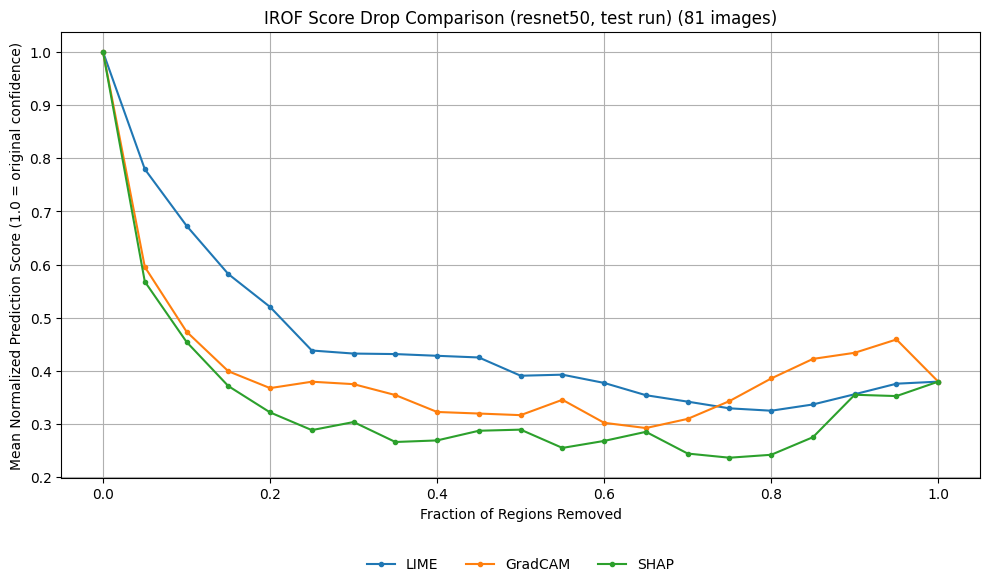

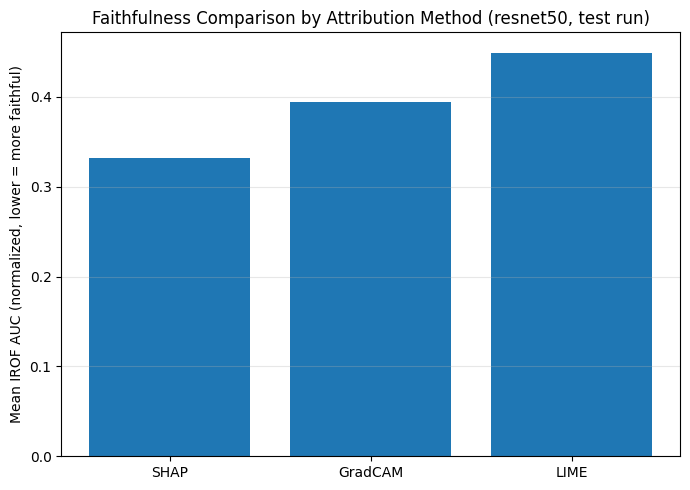

[mem after unloading resnet50] allocated=0.02 GB  reserved=0.04 GB

  Faithfulness (IROF) | Model: efficientnetb0


Running faithfulness (IROF) test run on 81 images 



Collected 243 IROF measurements
Saved per-image results to /data/ramdhavb/results/irof_full_efficientnetb0_test_2026-10-17.csv
Saved summary to /data/ramdhavb/results/irof_summary_efficientnetb0_test_2026-10-17.csv

=== Faithfulness (IROF) summary | efficientnetb0 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.3100,0.2399,81
0,GradCAM,0.3206,0.2503,81
1,LIME,0.4030,0.2375,81


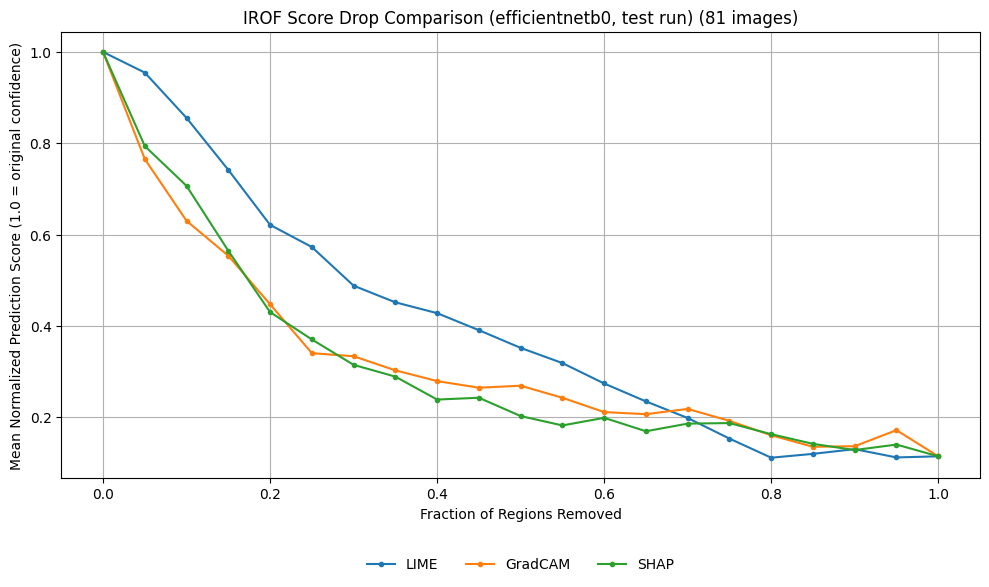

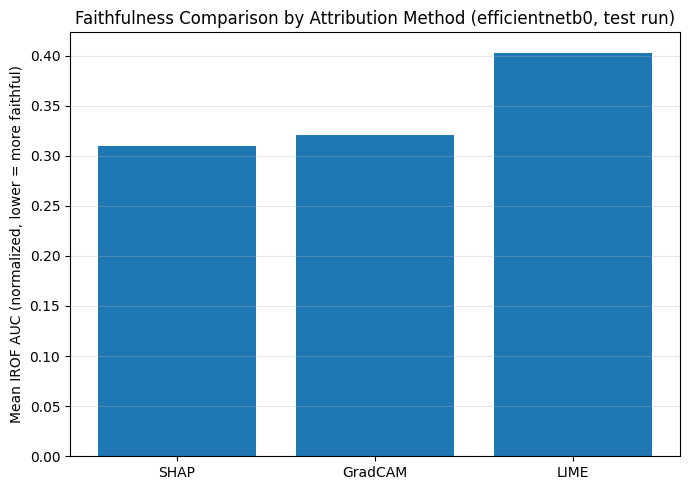

[mem after unloading efficientnetb0] allocated=0.02 GB  reserved=0.04 GB

=== Combined IROF summary (all models) ===


,model,method,mean_irof_auc,std_irof_auc,n_images
2,efficientnetb0,SHAP,0.3100,0.2399,81
0,efficientnetb0,GradCAM,0.3206,0.2503,81
1,efficientnetb0,LIME,0.4030,0.2375,81
5,resnet50,SHAP,0.3314,0.3481,81
3,resnet50,GradCAM,0.3946,0.2756,81
4,resnet50,LIME,0.4492,0.3865,81


In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_trapz = getattr(np, "trapezoid", None) or np.trapz

all_irof_dfs = []
irof_curves_by_model = {}

for model_name in MODEL_NAMES:
    print(f"\n{'='*60}\n  Faithfulness (IROF) | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(DRIVE_MODEL_DIR, f"{model_name}_best_model.pth")
    model = mm.load_model(model_name, drive_weight_path, device)

    engine = att_engine.AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    method_maps = load_attribution_maps(SAVE_DIR, model_name)
    N_FAITHFULNESS_IMAGES = len(next(iter(method_maps.values())))
    faithfulness_samples = idrid_subset[:N_FAITHFULNESS_IMAGES]

    predicted_labels = get_predicted_labels(model, faithfulness_samples, device)

    print(f"Running faithfulness (IROF) test run on {N_FAITHFULNESS_IMAGES} images ")

    full_irof_df, irof_curves, irof_random_curves = run_irof_evaluation(
        model, faithfulness_samples, predicted_labels, method_maps, device=device, dataset_mean=dataset_mean, 
    )

    full_irof_df['model'] = model_name
    all_irof_dfs.append(full_irof_df)
    irof_curves_by_model[model_name] = irof_curves

    print(f"\nCollected {len(full_irof_df)} IROF measurements")

    irof_summary = summarize_and_save_irof(
        full_irof_df,
        results_dir=RESULTS_DIR,
        tag=f"{model_name}_test"
    )

    print(f"\n=== Faithfulness (IROF) summary | {model_name} ===")
    print("    (lower mean_irof_auc = confidence drops faster once top-attributed regions")
    print("     are removed = more faithful explanation)\n")
    display(irof_summary)

    plot_irof_curves(irof_curves, N_FAITHFULNESS_IMAGES, title_suffix=f" ({model_name}, test run)")
    print()
    plot_irof_bar(irof_summary, title_suffix=f" ({model_name}, test run)")

    del method_maps, irof_random_curves
    mm.unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    mm.gpu_mem_report(f"after unloading {model_name}")

full_irof_df_all_models = pd.concat(all_irof_dfs, ignore_index=True)
combined_irof_summary = (
    full_irof_df_all_models.groupby(['model', 'method'])
    .agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'), n_images=('irof_auc', 'count'))
    .reset_index()
    .sort_values(['model', 'mean_irof_auc'])
)

combined_irof_summary['mean_irof_auc'] = combined_irof_summary['mean_irof_auc'].round(4)
combined_irof_summary['std_irof_auc'] = combined_irof_summary['std_irof_auc'].round(4)

print("\n=== Combined IROF summary (all models) ===")
display(combined_irof_summary)

In [25]:
irof_mean = {mn: {meth: np.mean(lst, axis=0) for meth, lst in c.items()} for mn, c in irof_curves_by_model.items()}
with open(os.path.join(RESULTS_DIR, "irof_mean_curves.pkl"), "wb") as f:
    pickle.dump(irof_mean, f)
print("Saved IROF curves for", list(irof_mean))

Saved IROF curves for ['resnet50', 'efficientnetb0']


Combined IROF summary:


,model,method,mean_irof_auc,std_irof_auc,n_images
0,efficientnetb0,GradCAM,0.3206,0.2503,81
1,efficientnetb0,LIME,0.4030,0.2375,81
2,efficientnetb0,SHAP,0.3100,0.2399,81
3,resnet50,GradCAM,0.3946,0.2756,81
4,resnet50,LIME,0.4492,0.3865,81
5,resnet50,SHAP,0.3314,0.3481,81


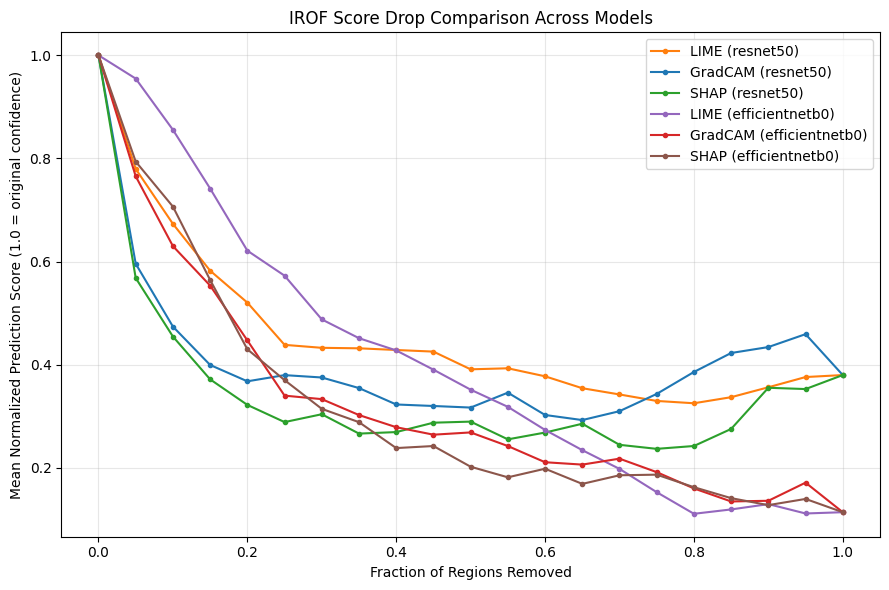

Saved to /data/ramdhavb/results/figures/irof_curves_combined_single_axis.png


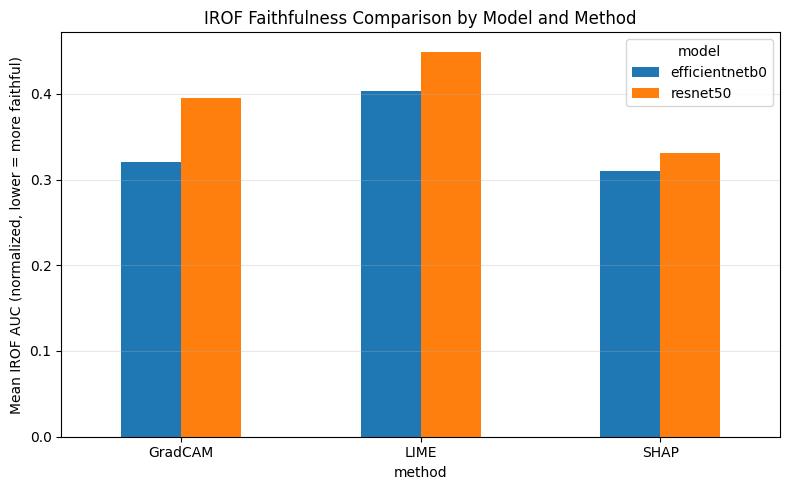


Saved combined figures + summary to /data/ramdhavb/results/figures


In [26]:
os.makedirs(FIGURES_DIR, exist_ok=True)

combined_irof_df = pd.concat(all_irof_dfs, ignore_index=True)
combined_summary = (
    combined_irof_df.groupby(['model', 'method'])
    .agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'), n_images=('irof_auc', 'count'))
    .reset_index()
)
combined_summary['mean_irof_auc'] = combined_summary['mean_irof_auc'].round(4)
combined_summary['std_irof_auc'] = combined_summary['std_irof_auc'].round(4)

combined_summary.to_csv(os.path.join(RESULTS_DIR, "irof_summary_combined.csv"), index=False)
print("Combined IROF summary:")
display(combined_summary)

# IROF Curves
model_names_present = list(irof_curves_by_model.keys())
method_names = sorted({m for curves in irof_curves_by_model.values() for m in curves})
 
# One distinct color per (model, method) combination
combos = [(model_name, method_name) for model_name in model_names_present for method_name in method_names]
palette = plt.get_cmap("tab10")
combo_colors = {combo: palette(i) for i, combo in enumerate(combos)}
 
fig, ax = plt.subplots(figsize=(9, 6))
 
for model_name in model_names_present:
    curves = irof_curves_by_model[model_name]
    n_points = len(next(iter(curves.values()))[0])
    fraction_removed = np.linspace(0, 1, n_points)
 
    for method_name, curve_list in curves.items():
        mean_curve = np.array(curve_list).mean(axis=0)
        ax.plot(
            fraction_removed, mean_curve,
            marker="o", markersize=3,
            color=combo_colors[(model_name, method_name)],
            label=f"{method_name} ({model_name})",
        )
 
ax.set_xlabel("Fraction of Regions Removed")
ax.set_ylabel("Mean Normalized Prediction Score (1.0 = original confidence)")
ax.set_title("IROF Score Drop Comparison Across Models")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")
 
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "irof_curves_combined_single_axis.png"), dpi=300, bbox_inches="tight")
plt.show()
 
print(f"Saved to {os.path.join(FIGURES_DIR, 'irof_curves_combined_single_axis.png')}")
# Figure 2: IROF mean AUC bar chart
pivot_df = combined_summary.pivot(index='method', columns='model', values='mean_irof_auc')

ax = pivot_df.plot(kind='bar', figsize=(8, 5), rot=0)
ax.set_xlabel("method")
ax.set_ylabel("Mean IROF AUC (normalized, lower = more faithful)")
ax.set_title("IROF Faithfulness Comparison by Model and Method")
ax.legend(title="model")
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "irof_bar_combined.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"\nSaved combined figures + summary to {FIGURES_DIR}")

# **RISE Deletion and Insetion**

Aknowledgements: [Official RISE Github Repository](https://github.com/eclique/RISE/blob/master/evaluation.py#L15)

In [27]:
HW = 224 * 224  #image area

In [28]:
def gkern(klen, nsig):
    """Returns a Gaussian kernel array.
    Convolution with it results in image blurring."""
    # create nxn zeros
    inp = np.zeros((klen, klen))
    # set element at the middle to one, a dirac delta
    inp[klen//2, klen//2] = 1
    # gaussian-smooth the dirac, resulting in a gaussian filter mask
    k = gaussian_filter(inp, nsig)
    kern = np.zeros((3, 3, klen, klen))
    kern[0, 0] = k
    kern[1, 1] = k
    kern[2, 2] = k
    return torch.from_numpy(kern.astype('float32'))

def auc(arr):
    """Returns normalized Area Under Curve of the array."""
    arr = np.asarray(arr)
    return float((arr.sum() - arr[0] / 2 - arr[-1] / 2) / (arr.shape[0] - 1))

In [29]:
class CausalMetric():

    def __init__(self, model, mode, step, substrate_fn):
        """Create deletion/insertion metric instance."""
        assert mode in ['del', 'ins']
        self.model = model
        self.mode = mode
        self.step = step
        self.substrate_fn = substrate_fn

    def single_run(self, img_tensor, explanation):
        with torch.no_grad():
            pred = self.model(img_tensor.to(device))
            top, c = torch.max(pred,1)
            c = c.cpu().numpy()[0]
            n_steps = (HW+self.step-1) // self.step

            if self.mode == 'del':
                start = img_tensor.clone()
                finish = self.substrate_fn(img_tensor)
            elif self.mode == 'ins':
                start = self.substrate_fn(img_tensor)
                finish = img_tensor.clone()

            scores = np.empty(n_steps +1)
            # Coordinates of pixels in order of decreasing saliency
            salient_order = np.flip(np.argsort(explanation.reshape(-1, HW), axis=1), axis=-1)
            for i in range(n_steps + 1):
                pred = self.model(start.to(device))
                scores[i] = pred[0,c].item()
                if i < n_steps: 
                    coords = salient_order[:, self.step*i:self.step*(i + 1)]
                    start.cpu().numpy().reshape(1,3,HW)[0,:,coords] = finish.cpu().numpy().reshape(1,3,HW)[0,:,coords]
        return scores


**Configuration cell**

In [30]:
STEP = 224
KLEN, KSIG= 11,5
kern= gkern(KLEN,KSIG)
blur = lambda x: F.conv2d(x, kern, padding=KLEN//2)
insertion_metric = lambda m: CausalMetric(m, 'ins', STEP, substrate_fn=blur)
deletion_metric = lambda m: CausalMetric(m, 'del', STEP, substrate_fn=torch.zeros_like)

def maybe_break_ties(a,seed, tie_break):
    a = np.asarray(a, dtype=np.float64)
    return a + 1e-9*np.random.RandomState(seed).rand(*a.shape) if tie_break else a

**Running with RISE tie-break**

RISE with original tie breaking rule


img0 (Random): del=0.5457 and ins=0.5457 (these should be matching)


RISE with original tie breaking rule


img0 (Random): del=0.8734 and ins=0.8734 (these should be matching)


,model,method,del_auc,ins_auc,n
0,efficientnetb0,GradCAM,0.1975,0.4292,81
1,efficientnetb0,LIME,0.2279,0.3692,81
2,efficientnetb0,Random,0.1477,0.3124,81
3,efficientnetb0,SHAP,0.1853,0.4400,81
4,resnet50,GradCAM,0.1996,0.4469,81
5,resnet50,LIME,0.1902,0.3042,81
6,resnet50,Random,0.1774,0.2867,81
7,resnet50,SHAP,0.1696,0.4756,81


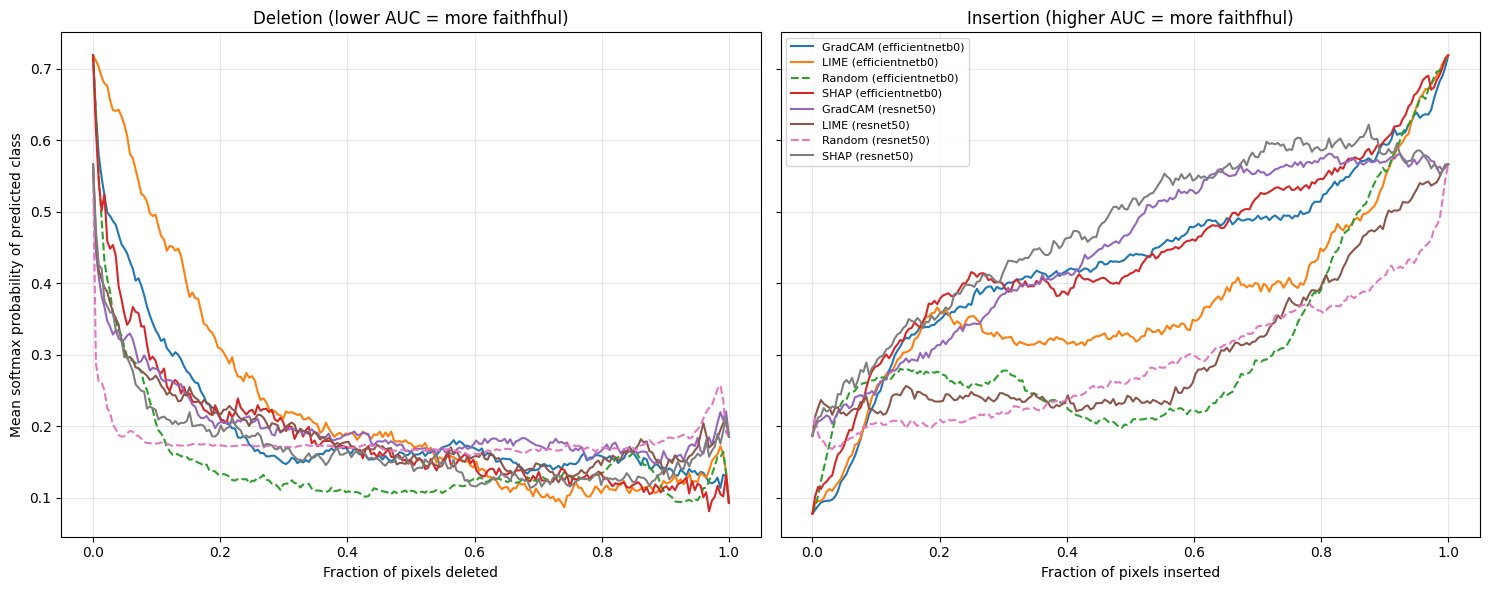

In [31]:
TIE_BREAK = False # This uses the original RISE tie-breaking rule

rows, curves = [], {}
for model_name in MODEL_NAMES:
    print("RISE with original tie breaking rule")

    # Loading the model
    base = mm.load_model(model_name, os.path.join(DRIVE_MODEL_DIR, f"{model_name}_best_model.pth"), device)
    base.eval()
    model = nn.Sequential(base, nn.Softmax(dim=1)).to(device).eval()

    # Load the attribution maps
    method_maps = load_attribution_maps(SAVE_DIR, model_name)
    n_images = len(next(iter(method_maps.values())))
    samples = idrid_subset[:n_images]

    # Build the insertion and deeltion metrics
    ins_m = insertion_metric(model)
    del_m = deletion_metric(model)

    store = {(m,mode): [] for m in list(method_maps)+["Random"] for mode in ("del","ins")}
    for i in tqdm(range(n_images), desc=model_name, ncols=90):
        x = test_transform(PILImage.fromarray(samples[i][0])).unsqueeze(0).cpu()
        maps = {m: np.asarray(method_maps[m][i]) for m in method_maps}

        # Random baseline map to compare against
        maps["Random"] = np.random.RandomState(1000+ i).rand(224,224)

        for m, a in maps.items():
            assert a.shape == (224,224), (m, a.shape)
            a = maybe_break_ties(a=a, seed=i,tie_break=TIE_BREAK)

            # Run the deletion and insertion metrics
            s_del = del_m.single_run(x,a)
            s_ins = ins_m.single_run(x,a)
            store[(m,"del")].append(s_del); store[(m,"ins")].append(s_ins)

            #Record the image's AUCs
            rows.append(dict(model=model_name, method=m, image_index=i, p_orig=s_del[0], del_auc=auc(s_del), ins_auc=auc(s_ins)))

        if i == 0:
            print(f"img0 ({m}): del={s_del[0]:.4f} and ins={s_ins[-1]:.4f} (these should be matching)")

    # Average the per-image curves into one mean curve per (model,method,mode)
    for k, v in store.items():
        curves[(model_name,)+k] = np.mean(v,axis=0)

    mm.unload_model(model=base, engine=None, engine_cache=None)
    del model, method_maps

df = pd.DataFrame(rows)
summary = df.groupby(["model", "method"]).agg(del_auc=("del_auc","mean"), ins_auc=("ins_auc","mean"),
                                              n=("del_auc","count")).round(4).reset_index()
display(summary)
df.to_csv(os.path.join(RESULTS_DIR, f"rise_original_full.csv"), index=False)
summary.to_csv(os.path.join(RESULTS_DIR, f"rise_original_summary.csv"),index=False)

# X-axis: fraction of pixels flipped at each step
n_steps = (HW + STEP -1) // STEP
xs = np.arange(n_steps+1)/n_steps

fig, axes = plt.subplots(1,2, figsize=(15,6), sharey=True)
for ci, (key, curve) in enumerate(sorted(curves.items())):
    mname, meth, model = key
    ax = axes[0 if model =="del" else 1]
    ax.plot(xs, curve, "--" if meth=="Random" else "-", label=f"{meth} ({mname})")
    
axes[0].set_title("Deletion (lower AUC = more faithfhul)")
axes[0].set_xlabel("Fraction of pixels deleted")
axes[1].set_title("Insertion (higher AUC = more faithfhul)")
axes[1].set_xlabel("Fraction of pixels inserted")
axes[0].set_ylabel("Mean softmax probability of predicted class")

for ax in axes: ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "rise_original_curves.png"), dpi=300, bbox_inches="tight")
plt.show()


In [32]:
rise_curves = {k: np.asarray(v) for k, v in curves.items() if k[1] !="Random"}
with open(os.path.join(RESULTS_DIR, "rise_original_mean_curves.pkl"), "wb") as f:
    pickle.dump(rise_curves, f)
print("Saved", len(rise_curves), "RISE curves")

Saved 12 RISE curves


**Combined Curves figure to plot each of the curves side-by-side**

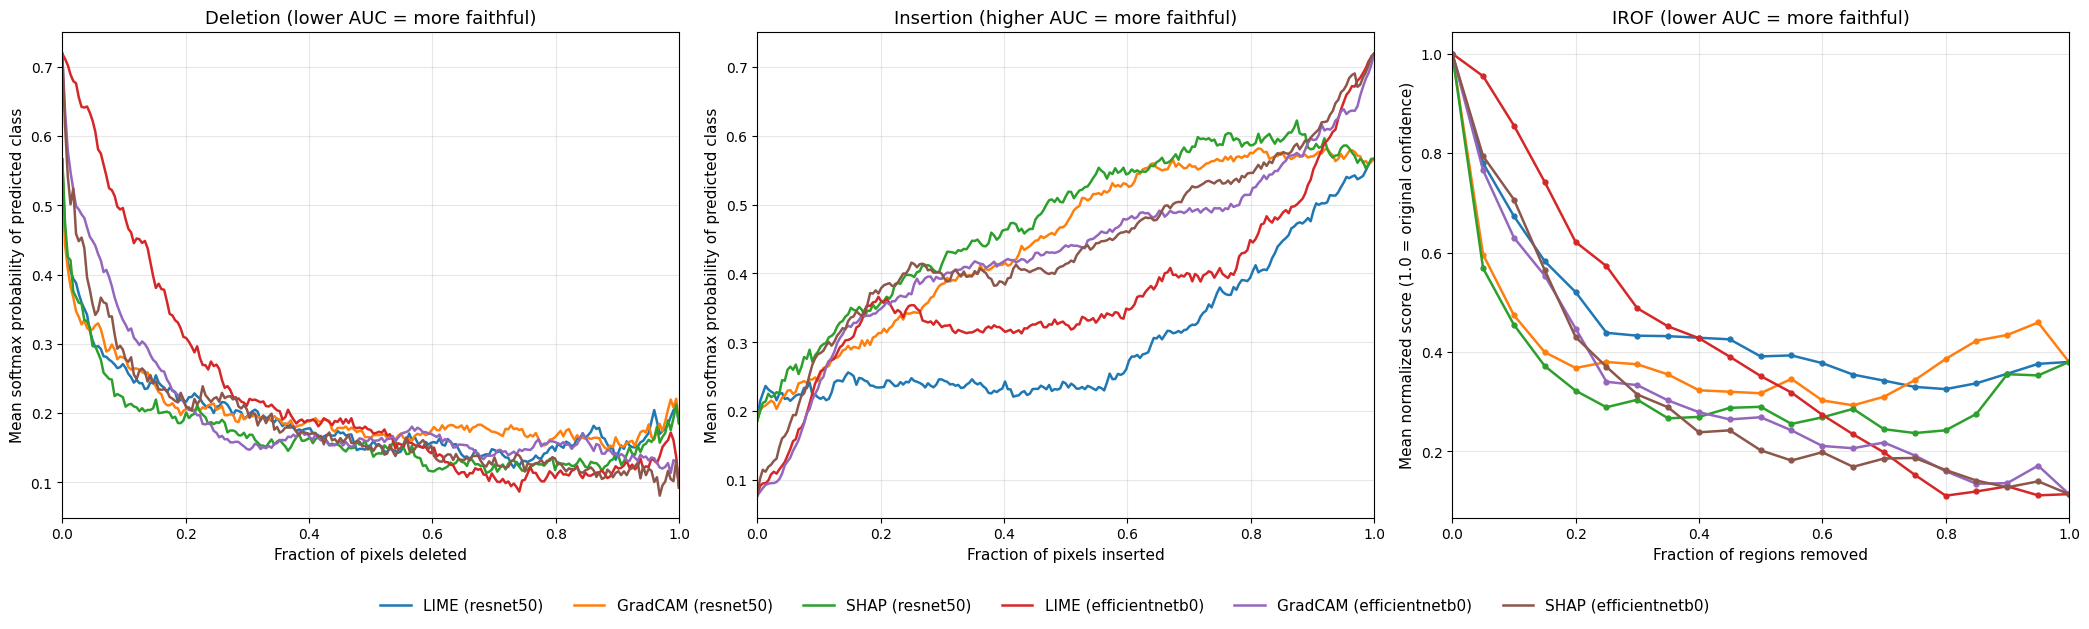

Saved /data/ramdhavb/results/figures/faithfulness_curves_combined.png


In [33]:
with open(os.path.join(RESULTS_DIR, "rise_original_mean_curves.pkl"), "rb") as f:
    rise_curves = pickle.load(f)
with open(os.path.join(RESULTS_DIR, "irof_mean_curves.pkl"), "rb") as f:
    irof_mean = pickle.load(f)

METHODS = ["LIME", "GradCAM", "SHAP"]
palette = plt.get_cmap("tab10")
PAIR_COLORS = {(mn, meth): palette(i) for i, (mn, meth) in
               enumerate([(mn, meth) for mn in MODEL_NAMES for meth in METHODS])}

n_steps = (HW + STEP - 1) // STEP
xs_rise = np.arange(n_steps + 1) / n_steps

fig, axes = plt.subplots(1, 3, figsize=(21, 6.2))

for mode, ax, title, xl in [("del", axes[0], "Deletion (lower AUC = more faithful)", "Fraction of pixels deleted"),
                            ("ins", axes[1], "Insertion (higher AUC = more faithful)", "Fraction of pixels inserted")]:
    for mn in MODEL_NAMES:
        for meth in METHODS:
            ax.plot(xs_rise, rise_curves[(mn, meth, mode)], "-", color=PAIR_COLORS[(mn, meth)],
                    linewidth=1.8, label=f"{meth} ({mn})")
    ax.set_title(title, fontsize=13); ax.set_xlabel(xl, fontsize=11)
    ax.set_ylabel("Mean softmax probability of predicted class", fontsize=11)

ax = axes[2]
for mn in MODEL_NAMES:
    for meth in METHODS:
        y = irof_mean[mn][meth]
        ax.plot(np.linspace(0, 1, len(y)), y, "-", color=PAIR_COLORS[(mn, meth)],
                marker="o", markersize=3.5, linewidth=1.8, label=f"{meth} ({mn})")
ax.set_title("IROF (lower AUC = more faithful)", fontsize=13)
ax.set_xlabel("Fraction of regions removed", fontsize=11)
ax.set_ylabel("Mean normalized score (1.0 = original confidence)", fontsize=11)

for a in axes:
    a.set_xlim(0, 1); a.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), fontsize=11, frameon=False,
           bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1))

out = os.path.join(FIGURES_DIR, "faithfulness_curves_combined.png")
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("Saved", out)